In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import spacy
from textblob import TextBlob

%matplotlib inline

### **1. Importación de datos (detalles de productos)**

In [2]:
data = pd.read_csv('amazon.csv')

In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

In [4]:
# Mantenemos en el df los tweets sin NA en la columna text_cleaned
data = data[data['review_content'].notna()]

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           1465 non-null   object
 1   product_name         1465 non-null   object
 2   category             1465 non-null   object
 3   discounted_price     1465 non-null   object
 4   actual_price         1465 non-null   object
 5   discount_percentage  1465 non-null   object
 6   rating               1465 non-null   object
 7   rating_count         1463 non-null   object
 8   about_product        1465 non-null   object
 9   user_id              1465 non-null   object
 10  user_name            1465 non-null   object
 11  review_id            1465 non-null   object
 12  review_title         1465 non-null   object
 13  review_content       1465 non-null   object
 14  img_link             1465 non-null   object
 15  product_link         1465 non-null   object
dtypes: obj

In [6]:
data.head()

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...


### **Hay bastantes datos, así que se hará una prueba inicial con 200 mil datos**

In [7]:
data = data.head(100)

In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   product_id           100 non-null    object
 1   product_name         100 non-null    object
 2   category             100 non-null    object
 3   discounted_price     100 non-null    object
 4   actual_price         100 non-null    object
 5   discount_percentage  100 non-null    object
 6   rating               100 non-null    object
 7   rating_count         100 non-null    object
 8   about_product        100 non-null    object
 9   user_id              100 non-null    object
 10  user_name            100 non-null    object
 11  review_id            100 non-null    object
 12  review_title         100 non-null    object
 13  review_content       100 non-null    object
 14  img_link             100 non-null    object
 15  product_link         100 non-null    object
dtypes: object

In [9]:
nlp = spacy.load("en_core_web_sm")

In [ ]:
def normalizar(text):
    doc = nlp(text)
    words = [word.lemma_ for word in doc if (len(word) > 3 and not word.is_punct and not word.is_stop 
                                             and not word.text.startswith('@') and not word.text.startswith('http'))]
    
    doc = " ".join(word for word in words) 
    return doc

In [11]:
data['content_clean'] = data.apply(lambda x: normalizar(x['review_content']), axis=1)

In [12]:
data.head(10)

,product_id,product_name,category,discounted_price,actual_price,discount_percentage,rating,rating_count,about_product,user_id,user_name,review_id,review_title,review_content,img_link,product_link,content_clean
0,B07JW9H4J1,Wayona Nylon Braided USB to Lightning Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹399,"₹1,099",64%,4.2,"24,269",High Compatibility : Compatible With iPhone 12...,"AG3D6O4STAQKAY2UVGEUV46KN35Q,AHMY5CWJMMK5BJRBB...","Manav,Adarsh gupta,Sundeep,S.Sayeed Ahmed,jasp...","R3HXWT0LRP0NMF,R2AJM3LFTLZHFO,R6AQJGUP6P86,R1K...","Satisfied,Charging is really fast,Value for mo...",Looks durable Charging is fine tooNo complains...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Wayona-Braided-WN3LG1-Sy...,look durable Charging fine toono complain Char...
1,B098NS6PVG,Ambrane Unbreakable 60W / 3A Fast Charging 1.5...,Computers&Accessories|Accessories&Peripherals|...,₹199,₹349,43%,4.0,"43,994","Compatible with all Type C enabled devices, be...","AECPFYFQVRUWC3KGNLJIOREFP5LQ,AGYYVPDD7YG7FYNBX...","ArdKn,Nirbhay kumar,Sagar Viswanathan,Asp,Plac...","RGIQEG07R9HS2,R1SMWZQ86XIN8U,R2J3Y1WL29GWDE,RY...","A Good Braided Cable for Your Type C Device,Go...",I ordered this cable to connect my phone to An...,https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Ambrane-Unbreakable-Char...,order cable connect phone Android Auto cable s...
2,B096MSW6CT,Sounce Fast Phone Charging Cable & Data Sync U...,Computers&Accessories|Accessories&Peripherals|...,₹199,"₹1,899",90%,3.9,"7,928",【 Fast Charger& Data Sync】-With built-in safet...,"AGU3BBQ2V2DDAMOAKGFAWDDQ6QHA,AESFLDV2PT363T2AQ...","Kunal,Himanshu,viswanath,sai niharka,saqib mal...","R3J3EQQ9TZI5ZJ,R3E7WBGK7ID0KV,RWU79XKQ6I1QF,R2...","Good speed for earlier versions,Good Product,W...","Not quite durable and sturdy,https://m.media-a...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Sounce-iPhone-Charging-C...,durable sturdy amazon.com image WEBP_402378 im...
3,B08HDJ86NZ,boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...,Computers&Accessories|Accessories&Peripherals|...,₹329,₹699,53%,4.2,"94,363",The boAt Deuce USB 300 2 in 1 cable is compati...,"AEWAZDZZJLQUYVOVGBEUKSLXHQ5A,AG5HTSFRRE6NL3M5S...","Omkar dhale,JD,HEMALATHA,Ajwadh a.,amar singh ...","R3EEUZKKK9J36I,R3HJVYCLYOY554,REDECAZ7AMPQC,R1...","Good product,Good one,Nice,Really nice product...","Good product,long wire,Charges good,Nice,I bou...",https://m.media-amazon.com/images/I/41V5FtEWPk...,https://www.amazon.in/Deuce-300-Resistant-Tang...,good product long wire charge good Nice buy ca...
4,B08CF3B7N1,Portronics Konnect L 1.2M Fast Charging 3A 8 P...,Computers&Accessories|Accessories&Peripherals|...,₹154,₹399,61%,4.2,"16,905",[CHARGE & SYNC FUNCTION]- This cable comes wit...,"AE3Q6KSUK5P75D5HFYHCRAOLODSA,AFUGIFH5ZAFXRDSZH...","rahuls6099,Swasat Borah,Ajay Wadke,Pranali,RVK...","R1BP4L2HH9TFUP,R16PVJEXKV6QZS,R2UPDB81N66T4P,R...","As good as original,Decent,Good one for second...","Bought this instead of original apple, does th...",https://m.media-amazon.com/images/W/WEBP_40237...,https://www.amazon.in/Portronics-Konnect-POR-1...,buy instead original apple work 150rs fast app...
5,B08Y1TFSP6,pTron Solero TB301 3A Type-C Data and Fast Cha...,Computers&Accessories|Accessories&Peripherals|...,₹149,"₹1,000",85%,3.9,"24,871",Fast Charging & Data Sync: Solero TB301 Type-C...,"AEQ2YMXSZWEOHK2EHTNLOS56YTZQ,AGRVINWECNY7323CW...","Jayesh,Rajesh k.,Soopy,amazon customer,Aman,Sh...","R7S8ANNSDPR40,R3CLZFLHVJU26P,RFF7U7MPQFUGR,R1M...","It's pretty good,Average quality,very good and...","It's a good product.,Like,Very good item stron...",https://m.media-amazon.com/images/I/31wOPjcSxl...,https://www.amazon.in/Solero-TB301-Charging-48...,"good product ,like good item strong useful cab..."
6,B08WRWPM22,"boAt Micro USB 55 Tangle-free, Sturdy Micro US...",Computers&Accessories|Accessories&Peripherals|...,₹176.63,₹499,65%,4.1,"15,188",It Ensures High Speed Transmission

### **2. Análisis de Sentimientos**

Se puede utilizar textblob del paquete Python para calcular los valores de polaridad de los tweets individuales.
* Empezamos creando objetos textblob, que asignan valores de polaridad a los tweets.
* Luego se identifica el valor de polaridad utilizando el atributo .polarity del objeto texblob.

In [61]:
# definimos una funcion para analizar los sentimientos en cada texto del tweet
def analize_sentiment(tweet):
    '''
    Función de utilidad para clasificar la polaridad de un tweet
     usando textblob.
    '''
    analysis = TextBlob(tweet)
    if analysis.sentiment.polarity > 0:
        return 1
    elif analysis.sentiment.polarity == 0:
        return 0
    else:
        return -1

La forma en que funciona es que textblob ya proporciona un analizador entrenado (mucho más facil). **Textblob** puede trabajar con diferentes modelos de aprendizaje automático utilizados en el procesamiento del lenguaje natural. De todos modos, volviendo al código, solo agregaremos una columna adicional a nuestros datos. Esta columna contendrá el análisis de sentimiento y podemos trazar el dataframe para ver la actualización:

In [62]:
# Creamos una columna con el resultado del análisis:
data['SA'] = np.array([ analize_sentiment(rev) for rev in data['content_clean'] ])

data.head()

,rotten_tomatoes_link,critic_name,top_critic,publisher_name,review_type,review_score,review_date,review_content,content_clean,SA
0,m/0814255,Andrew L. Urban,False,Urban Cinefile,Fresh,NaN,2010-02-06,A fantasy adventure that fuses Greek mythology...,fantasy adventure fuse greek mythology contemp...,1
1,m/0814255,Louise Keller,False,Urban Cinefile,Fresh,NaN,2010-02-06,"Uma Thurman as Medusa, the gorgon with a coiff...",thurman medusa gorgon coiffure writhe snake st...,0
2,m/0814255,NaN,False,FILMINK (Australia),Fresh,NaN,2010-02-09,With a top-notch cast and dazzling special eff...,notch cast dazzle special effect tide teen har...,1
3,m/0814255,Ben McEachen,False,Sunday Mail (Australia),Fresh,3.5/5,2010-02-09,Whether audiences will get behind The Lightnin...,audience lightne thief hard predict overall en...,1
4,m/0814255,Ethan Alter,True,Hollywood Reporter,Rotten,NaN,2010-02-10,What's really lacking in The Lightning Thief i...,lack lightning thief genuine sense wonder thin...,1


In [9]:
# Cree un df que contenga el valor de polaridad y el texto del tweet
sentiment_df = data[['text_cleaned', 'SA']]

sentiment_df.head(15)

,text_cleaned,SA
0,trump have be ban from facebookcongratulation ...,0
1,coup attempt fallout trumpbanne trumpcensore t...,0
2,trumpbannedtrump ban from facebook indefinitely,0
3,mark zuckerberg ban realdonaldtrump from faceb...,0
4,facebook do the leastbanne cheeto two week bef...,0
5,so donaldtrump have be ban from facebook indef...,1
6,tromb be a dictator under the skin this be bal...,0
7,twitter tonight be like when scream child fina...,0
8,base on trump time see over the past year a ho...,-1
9,ohhhhh spot on trumpisacompletefailure trumpbanne,0


**Análisis de los resultados**

Para tener una forma sencilla de verificar los resultados, contaremos el número de tweets neutrales, positivos y negativos y extraeremos los porcentajes.

In [10]:
pos = len(sentiment_df[sentiment_df['SA'] > 0]. value_counts())
neu = len(sentiment_df[sentiment_df['SA'] == 0]. value_counts())
neg = len(sentiment_df[sentiment_df['SA'] < 0]. value_counts())
tot =  pos+neu+neg
#print (pos, neu, neg, pos+neu+neg)

Imprimimos los porcentajes:

In [11]:
# Visualizamos los %:

print("Porcentaje de tweets positivos : {}%".format(round(pos/tot*100,2)))
print("Porcentaje de tweets neutrales : {}%".format(round(neu/tot*100,2)))
print("Porcentaje de tweets negativos : {}%".format(round(neg/tot*100,2)))

Porcentaje de tweets positivos : 26.04%
Porcentaje de tweets neutrales : 56.45%
Porcentaje de tweets negativos : 17.51%


Estos valores de polaridad se pueden trazar en un histograma, lo que puede ayudar a resaltar el sentimiento general (es decir, más positividad o negatividad) hacia el sujeto.

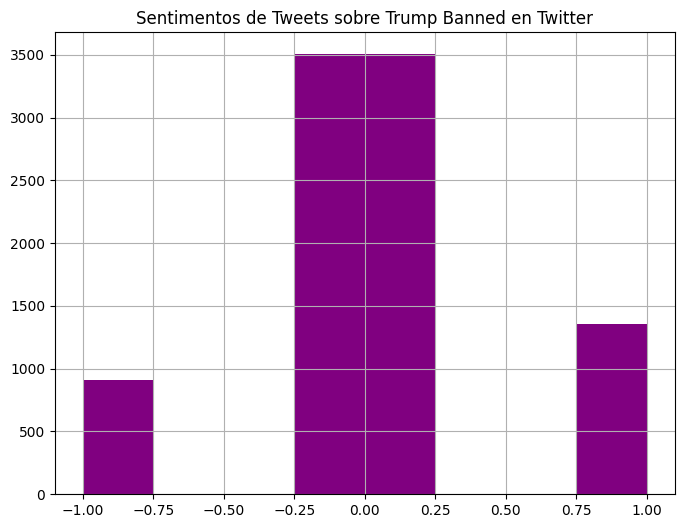

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))

# Plot histogram of the polarity values
sentiment_df.hist(bins=[-1, -0.75, -0.5, -0.25, 0.25, 0.5, 0.75, 1],
             ax=ax,
             color="purple")

plt.title("Sentimentos de Tweets sobre Trump Banned en Twitter")
plt.show()

### **3. Nube de Palabras (WordCloud)**

In [13]:
from PIL import Image
from wordcloud import WordCloud, STOPWORDS, ImageColorGenerator

In [14]:
text = " ".join(tweet for tweet in sentiment_df['text_cleaned'])
print ("Existen {} palabras al combinar todos los tweets limpios.".format(len(text)))

Existen 415826 palabras al combinar todos los tweets limpios.


In [15]:
stopwords = set(STOPWORDS)
# Eliminaremos las palabras de coleccon
stopwords.update(["trump", "trumpbanned", "wearetrump", "realdonaldtrump"])

# Generate a word cloud image
wordcloud = WordCloud(stopwords=stopwords, background_color="GhostWhite", width=800, height=800, margin=2,collocations=False,
                      font_step=2).generate(text)

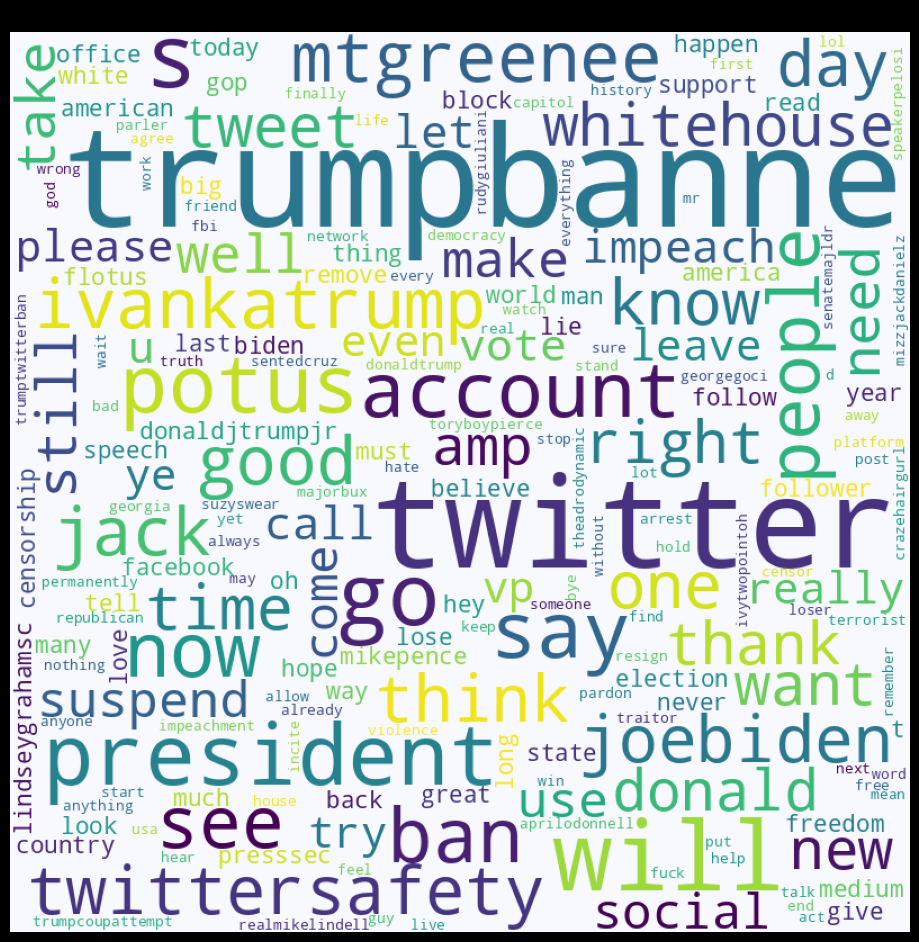

In [16]:
plt.figure(figsize=(16,9), facecolor='k')
plt.imshow(wordcloud)
plt.axis("off")
plt.tight_layout(pad=0)
plt.title("Wordcloud (Nube de Palabras) sobre Trump Banned en Twitter")
plt.show()

### **4. Ubicación de los tweets en un mapa**

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

import plotly.express as px
import plotly.io as pio

fig = px.scatter_geo(data, lat='Lat', lon='Lon',
                     color='place-country', #size='New cases', size_max=20,
                     hover_name='user-screen_name',
                     hover_data=[ 'text_cleaned',  'place-country',
                                 'user-location'], template='seaborn')

fig.update_layout(
    title_text = "Subconjunto de tweets con ubicación exacta",

    geo=dict(showframe=False, showcoastlines=False,
             projection_type='equirectangular'),

    annotations = [dict(x=-0.04, y=0.95, xref='paper', yref='paper',
        text='Del total de tweets, solo el ~ 7% incluye ' \
                'la ubicación exacta. Esta proporción se mantiene siempre.', showarrow = False)]
)

fig.update_geos(resolution=110, showcountries=True,
                lataxis_range=[-55, 90], lonaxis_range=[-180, 180])
fig.show()